In [41]:
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt


In [42]:
df=pd.read_csv("heart failure.csv")
df.head()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


In [3]:
df.shape

(299, 13)

In [4]:
df.isnull().sum()

age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0
dtype: int64

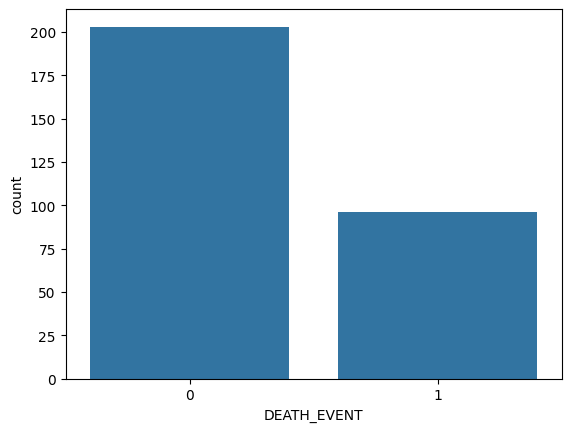

In [55]:
sns.countplot(x='DEATH_EVENT',data=df)
plt.show()

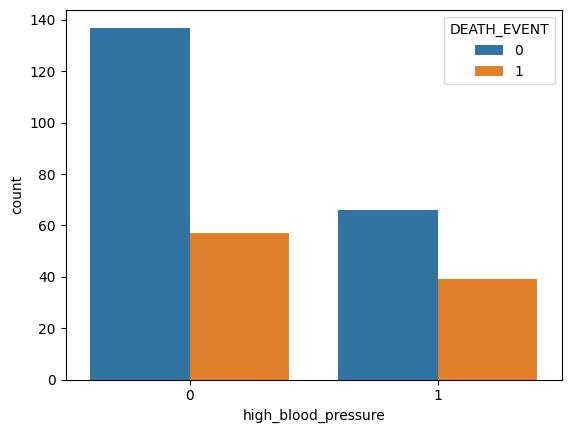

In [56]:
sns.countplot(x='high_blood_pressure',data=df,hue='DEATH_EVENT')
plt.show()

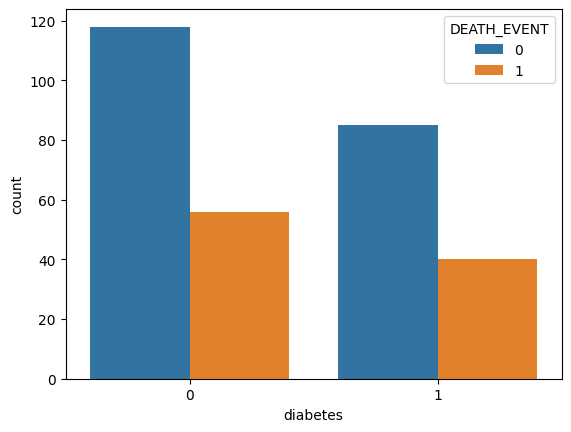

In [54]:
sns.countplot(x='diabetes',data=df,hue='DEATH_EVENT')
plt.show()

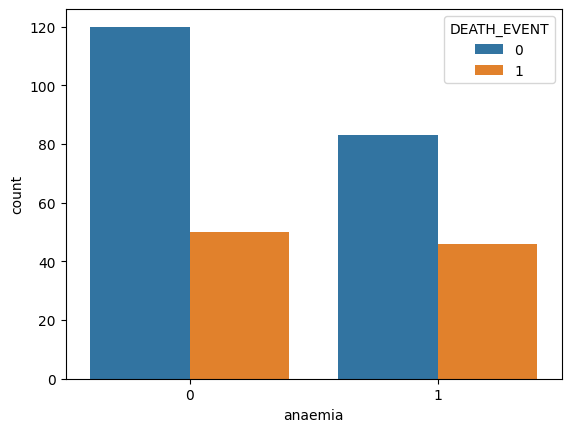

In [53]:
sns.countplot(x='anaemia',data=df,hue='DEATH_EVENT')
plt.show()

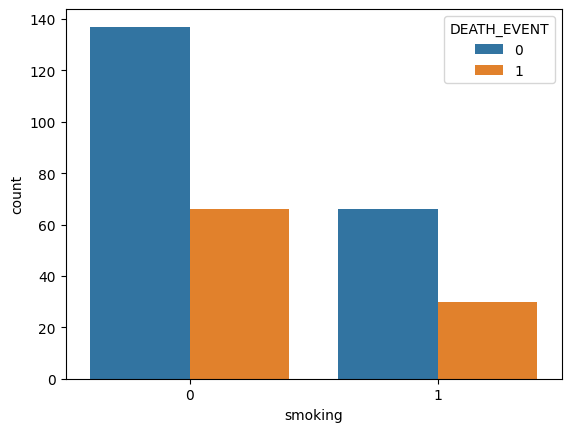

In [51]:
	
sns.countplot(x='smoking',data=df,hue='DEATH_EVENT')
plt.show()

In [10]:
from sklearn.model_selection import train_test_split
xtrain,xtest,ytrain,ytest=train_test_split(df.drop('DEATH_EVENT',axis=1),df[['DEATH_EVENT']],random_state=1,train_size=0.7)

In [11]:
xtrain.shape
xtrain.head()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time
14,49.0,1,80,0,30,1,427000.0,1.0,138,0,0,12
210,70.0,0,212,1,17,1,389000.0,1.0,136,1,1,188
236,75.0,0,119,0,50,1,248000.0,1.1,148,1,0,209
44,60.0,1,588,1,60,0,194000.0,1.1,142,0,0,33
163,50.0,1,2334,1,35,0,75000.0,0.9,142,0,0,126


In [12]:
xtest.shape
xtest.head()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time
173,50.0,1,115,0,20,0,189000.0,0.8,139,1,0,146
287,45.0,0,582,1,55,0,543000.0,1.0,132,0,0,250
51,53.0,1,91,0,20,1,418000.0,1.4,139,0,0,43
146,52.0,0,132,0,30,0,218000.0,0.7,136,1,1,112
214,65.0,1,135,0,35,1,290000.0,0.8,134,1,0,194


In [13]:
ytrain.shape
ytrain.head()

,DEATH_EVENT
14,0
210,0
236,0
44,1
163,1


In [14]:
ytest.shape
ytest.head()

,DEATH_EVENT
173,0
287,0
51,1
146,0
214,0


In [15]:
from sklearn.tree import DecisionTreeClassifier
dt=DecisionTreeClassifier()

In [16]:
dt.fit(xtrain,ytrain)


,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the curre

In [17]:
#Lets predict
pred=dt.predict(xtrain)#trainning accuracy
pred

array([0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0,
       1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1,
       1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0,
       0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0,
       0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0,
       1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1,
       0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1])

In [18]:
ytrain.head()

,DEATH_EVENT
14,0
210,0
236,0
44,1
163,1


In [19]:
ytrain['Pred']=pred

In [20]:
ytrain.head(10)

,DEATH_EVENT,Pred
14,0,0
210,0,0
236,0,0
44,1,1
163,1,1
292,0,0
117,0,0
258,0,0
41,1,1
79,0,0


In [21]:
dt.score(xtrain,ytrain['DEATH_EVENT'])

1.0

In [22]:
pred2=dt.predict(xtest)
pred2

array([0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1,
       1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0,
       1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1,
       1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0,
       0, 1])

In [23]:
dt.score(xtest,ytest)

0.8

In [24]:
ytest['Pred2']=pred2
ytest

,DEATH_EVENT,Pred2
173,0,0
287,0,0
51,1,0
146,0,0
214,0,0
...,...,...
122,0,0
246,1,0
278,0,0
251,0,0


In [25]:
#Confusion Matrix
from sklearn.metrics import classification_report,accuracy_score,confusion_matrix,RocCurveDisplay

In [26]:
print(classification_report(ytest['DEATH_EVENT'],pred2))

              precision    recall  f1-score   support

           0       0.86      0.86      0.86        64
           1       0.65      0.65      0.65        26

    accuracy                           0.80        90
   macro avg       0.76      0.76      0.76        90
weighted avg       0.80      0.80      0.80        90



In [27]:
cm=confusion_matrix(ytest['DEATH_EVENT'],pred2)
cm

array([[55,  9],
       [ 9, 17]])

<Axes: >

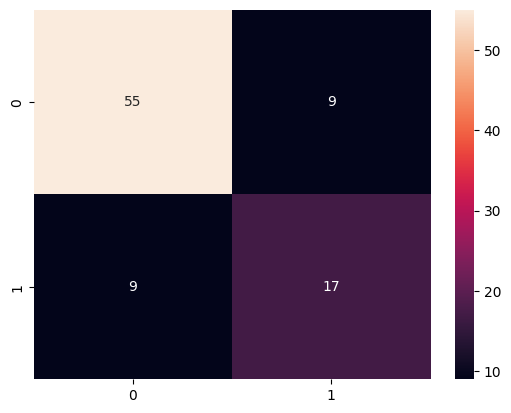

In [28]:
sns.heatmap(cm,annot=True)

In [29]:
from sklearn.metrics import accuracy_score
accuracy_score(ytest['DEATH_EVENT'],pred2)

0.8

In [30]:
confusion_matrix(ytest['DEATH_EVENT'],pred2).reshape(-1)

array([55,  9,  9, 17])

In [31]:
tp,fp,fn,tn=confusion_matrix(ytest['DEATH_EVENT'],pred2).reshape(-1)

In [32]:
tp

np.int64(55)

In [33]:
fp

np.int64(9)

In [34]:
fn

np.int64(9)

In [35]:
tn

np.int64(17)

In [36]:
acc=(tp+tn)/(tp+fp+tn+fn)
acc

np.float64(0.8)

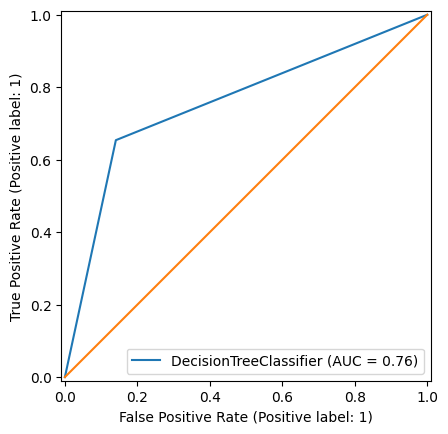

In [37]:
RocCurveDisplay.from_estimator(dt,xtest,ytest['DEATH_EVENT'])
plt.plot([0,1],[0,1])

Different Perfomance measure

In [38]:
#Accuracy
accuracy=(tp+tn)/(tp+fp+tn+fn)
accuracy

np.float64(0.8)

In [44]:
#Precision or positive predictive value(ppv)
precision=tp/(tp+fp)
precision

np.float64(0.859375)

In [45]:
#Sensitivity,Recall,hitrate or(True positive rate)
recall=tp/(tp+fn)
recall

np.float64(0.859375)

In [46]:
#False Positive rate (FPR) or 1-specificity
FPR=fp/(fp+tn)
FPR

np.float64(0.34615384615384615)

In [47]:
#Spepcificity,Selectivity or True Negative Rate
TNR=tn/(tn+fp)
TNR

np.float64(0.6538461538461539)

In [48]:
#threat score or critical success index (CSI)
CSI=tp/(tp+fn+fp)
CSI

np.float64(0.7534246575342466)

In [49]:
#False Discovery Rate (FDR)
FDR=fp/(tp+fp)
FDR

np.float64(0.140625)

In [50]:
#Harmonic Mean (F-measure)=
F_measure=(2*precision*recall)/(precision+recall)
F_measure

np.float64(0.859375)